# Deteksi Kerusakan Jalan · YOLO di VS Code / WSL2 (GTX 1080 Ti)

**Versi perbaikan instalasi:** memakai PyTorch **2.6.0 + CUDA 11.8** karena NVIDIA GTX 1080 Ti berarsitektur Pascal (sm_61), bukan versi `cu128` yang tidak lagi menyertakan dukungan Pascal pada build CUDA 12.8 terbaru.

### Sekali saja — siapkan environment khusus YOLO (terminal Ubuntu WSL2)

Jangan jalankan ini di virtual environment `.venv-tf` milik TensorFlow skripsi. Buka Ubuntu, lalu:

```bash
mkdir -p ~/deteksi-jalan
cd ~/deteksi-jalan
python3.10 -m venv .venv-yolo
source .venv-yolo/bin/activate
python -m pip install --upgrade pip ipykernel
python -m ipykernel install --user --name jalan-gpu --display-name "Python (YOLO GTX 1080 Ti)"
code .
```

Taruh notebook ini dalam folder `~/deteksi-jalan`, buka pada VS Code **WSL: Ubuntu**, lalu pilih kernel **Python (YOLO GTX 1080 Ti)**. Jika instalasi virtual environment gagal, pastikan paket sistem `python3.10-venv` tersedia. Gunakan Python 3.10 yang sudah dipasang di WSL.

### Cara menjalankan

1. **Sel 0:** instal dependensi (sekali saja, tunggu selesai). Unduhannya masih besar; `pip` disetel punya lebih banyak waktu dan percobaan resume. Restart kernel sekali setelah berhasil.
2. **Sel 1:** setup setiap kali buka notebook.
3. **Bagian A:** menyiapkan dataset (cukup sekali).
4. **Bagian C:** training YOLO.
5. **Bagian D:** evaluasi.

**Catatan:** keberhasilan instalasi tidak ditentukan dari status `torch.cuda.is_available()` saja; Sel 0 menguji komputasi langsung di CUDA. Cek ruang disk yang tersedia dengan `df -h` (disarankan sedikitnya 8 GB kosong untuk dependensi dan file sementara, di luar dataset).

**Struktur output:** direktori `data/`, `runs/`, `models/`, `eval/`, dan `hasil_evaluasi.csv` akan dibuat di folder project saat dieksekusi.


In [1]:
# Sel 0 · Instalasi pustaka untuk WSL2 GTX 1080 Ti (sekali saja, lalu Restart Kernel)
# Memilih CUDA 11.8 + PyTorch 2.6.0 agar dukungan Pascal (sm_61) tetap tersedia.
import os, sys, subprocess
from pathlib import Path

# JANGAN menimpa environment TensorFlow skripsi.
env_path = str(Path(sys.prefix).resolve())
if ".venv-tf" in env_path:
    raise RuntimeError(
        "Kernel masih menggunakan .venv-tf (TensorFlow skripsi). "
        "Buat .venv-yolo sesuai petunjuk di sel paling atas dan pilih kernel 'Python (YOLO GTX 1080 Ti)' terlebih dahulu."
    )

if sys.prefix == sys.base_prefix:
    raise RuntimeError("Kamu belum memilih virtual environment. Gunakan kernel Python (YOLO GTX 1080 Ti), bukan system Python.")

# Test dengan operasi CUDA nyata, sebab torch.cuda.is_available() belum cukup
# untuk memastikan build PyTorch mendukung GTX 1080 Ti (sm_61).
def torch_cuda_berfungsi():
    code = r"""
import torch
assert torch.cuda.is_available(), 'CUDA tidak tersedia'
cc = torch.cuda.get_device_capability(0)
x = torch.tensor([2.0], device='cuda')
assert (x * 3).item() == 6.0
print('GPU OK:', torch.cuda.get_device_name(0), '| CC:', cc, '| Torch:', torch.__version__)
"""
    return subprocess.run([sys.executable, "-c", code], capture_output=True, text=True)

cek = torch_cuda_berfungsi()
if cek.returncode != 0:
    print("PyTorch belum siap untuk GPU ini. Memasang PyTorch 2.6.0 + CUDA 11.8 ...")
    print("Informasi tes awal:", (cek.stderr or cek.stdout)[-600:])
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "torch", "torchvision"], check=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install",
        "--timeout", "120", "--retries", "15", "--resume-retries", "25",
        "torch==2.6.0", "torchvision==0.21.0",
        "--index-url", "https://download.pytorch.org/whl/cu118"
    ], check=True)
else:
    print(cek.stdout.strip())

# Install pustaka pendukung YOLO tanpa otomatis meng-upgrade Torch utama.
subprocess.run([
    sys.executable, "-m", "pip", "install",
    "--timeout", "120", "--retries", "15", "--resume-retries", "25",
    "ultralytics==8.4.190", "albumentations>=1.4.22", "imagehash", "gdown",
    "pandas", "scikit-learn", "matplotlib", "tqdm", "ipywidgets"
], check=True)

cek = torch_cuda_berfungsi()
if cek.returncode:
    raise RuntimeError("PyTorch terinstal, tetapi uji GPU belum lolos:\n" + (cek.stderr or cek.stdout)[-1400:])
print(cek.stdout.strip())
print("\nSelesai. Restart Kernel, lalu jalankan Sel 1.")


PyTorch belum siap untuk GPU ini. Memasang PyTorch 2.6.0 + CUDA 11.8 ...
Informasi tes awal: Traceback (most recent call last):
  File "<string>", line 2, in <module>
ModuleNotFoundError: No module named 'torch'



Looking in indexes: https://download.pytorch.org/whl/cu118
  Using cached filelock-4.1.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached networkx-3.4.2-py3-none-any.whl.metadata (6.3 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.2/23.2 MB 40.5 MB/s  0:00:00 eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 875.6/875.6 kB 16.0 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 44.9 MB/s  0:00:00 eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 663.9/663.9 MB 35.8 MB/s  0:00:15:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.9/417.9 MB 43.1 MB/s  0:00:09:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.4/168.4 MB 43.6 MB/s  0:00:03:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 MB 48.0 MB/s  0:00:01 eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.2/128.2 MB 46.4 MB/s  0:00:02:00:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [1]:
# Sel 1 · Setup (jalankan tiap buka VS Code atau restart kernel)
import os, sys, glob, shutil, random, zipfile, collections
PROJ = os.path.abspath(os.environ.get("PROJ_DIR", os.getcwd()))   # folder project = folder tempat notebook ini
DATA_DIR = os.path.join(PROJ, "data")
RAW, DS = os.path.join(DATA_DIR, "raw"), os.path.join(DATA_DIR, "rddc")
RUNS = os.path.join(PROJ, "runs")
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(RUNS, exist_ok=True)

import torch, ultralytics
print("Folder project:", PROJ)
print("Ultralytics", ultralytics.__version__, "| PyTorch", torch.__version__)
if torch.cuda.is_available():
    g = torch.cuda.get_device_properties(0)
    print(f"GPU: {g.name} | VRAM {g.total_memory / 1024**3:.1f} GB")
else:
    print("PERINGATAN: GPU NVIDIA tidak terdeteksi, training akan jalan di CPU dan bisa makan waktu berhari-hari.")

import numpy as np, pandas as pd
from PIL import Image
from IPython.display import display
CLASS_NAMES = ["Longitudinal Crack", "Lateral Crack", "Alligator Crack", "Pothole", "Other"]
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
SEED = 42
random.seed(SEED); np.random.seed(SEED)

Folder project: /home/galang/skripsi-training/Deteksi_Jalan
Ultralytics 8.4.190 | PyTorch 2.6.0+cu118
GPU: NVIDIA GeForce GTX 1080 Ti | VRAM 11.0 GB


---
## Bagian A · Persiapan data (cukup sekali)

Kalau file `data/rddc/data.yaml` sudah ada, bagian ini sudah pernah dijalankan. Langsung ke Bagian C.

In [2]:
# A1 · Ambil foto RDDC2024-ID: unduh zip (sekali), lalu ekstrak ke data/raw
# Sumber: link Google Drive di README github.com/endurancechallengeindonesia/RDDC2024-ID
RDDC_URL = "https://drive.google.com/file/d/1AbNe-dhK2ikaK05ATsPUcJXWW_bsz-pp/view"
zip_drive = os.path.join(DATA_DIR, "rddc2024id.zip")
if not (os.path.exists(zip_drive) and zipfile.is_zipfile(zip_drive)):
    import gdown
    try:
        gdown.download(id="1AbNe-dhK2ikaK05ATsPUcJXWW_bsz-pp", output=zip_drive, quiet=False)
    except Exception as e:
        print("gdown gagal:", e)
if not (os.path.exists(zip_drive) and zipfile.is_zipfile(zip_drive)):
    raise RuntimeError(f"Unduhan gagal (biasanya kuota unduh Google Drive lagi penuh).\n"
                       f"Unduh manual dari {RDDC_URL}\nlalu simpan sebagai {zip_drive} dan jalankan sel ini lagi.")

def daftar_foto(root):
    return [p for p in glob.glob(os.path.join(root, "**", "*"), recursive=True)
            if os.path.splitext(p)[1].lower() in IMG_EXT]

if not daftar_foto(RAW):
    shutil.rmtree(RAW, ignore_errors=True); os.makedirs(RAW)
    with zipfile.ZipFile(zip_drive) as z:
        z.extractall(RAW)
    for inner in glob.glob(os.path.join(RAW, "**", "*.zip"), recursive=True):   # kalau ada zip di dalam zip
        with zipfile.ZipFile(inner) as z:
            z.extractall(os.path.splitext(inner)[0])
        os.remove(inner)

for d, _, files in sorted(os.walk(RAW)):
    depth = d[len(RAW):].count(os.sep)
    if depth <= 2:
        print("  " * depth + (os.path.basename(d) or "raw") + "/", f"({len(files)} file)")
print("Total foto:", len(daftar_foto(RAW)))

raw/ (0 file)
  RDDC 2024_image/ (9048 file)
  RDDC 2024_label/ (7102 file)
Total foto: 9048


In [3]:
# A2 · Rapikan ke struktur Ultralytics (images/ dan labels/)
# Foto dan label diambil dari data/raw (hasil ekstrak A1), apa pun nama foldernya.
semua = glob.glob(os.path.join(RAW, "**", "*"), recursive=True)
images = sorted(p for p in semua if os.path.splitext(p)[1].lower() in IMG_EXT)
if not images:
    raise FileNotFoundError(f"Belum ada foto di {RAW}. Jalankan sel A1 dulu. "
                            "A1 akan mengunduh dan mengekstrak dataset ke folder data/raw.")
label_map = {}
for p in sorted((p for p in semua if p.lower().endswith(".txt")),
                key=lambda p: "label" not in p.lower()):   # file di folder Labels didahulukan
    label_map.setdefault(os.path.splitext(os.path.basename(p))[0], p)

img_dir, lbl_dir = os.path.join(DS, "images"), os.path.join(DS, "labels")
os.makedirs(img_dir, exist_ok=True); os.makedirs(lbl_dir, exist_ok=True)

rows, missing, seen, dup = [], 0, set(), 0
for p in images:
    stem = os.path.splitext(os.path.basename(p))[0]
    if stem in seen:
        dup += 1
        continue
    seen.add(stem)
    dst_img = os.path.join(img_dir, os.path.basename(p))
    if not os.path.exists(dst_img):
        shutil.copy2(p, dst_img)
    dst_lbl = os.path.join(lbl_dir, stem + ".txt")
    if stem in label_map:
        shutil.copy2(label_map[stem], dst_lbl)
    else:
        missing += 1
        open(dst_lbl, "w").close()   # tanpa label = foto tanpa kerusakan
    rows.append({"stem": stem, "image": dst_img, "label": dst_lbl})

df = pd.DataFrame(rows)
print(f"Jumlah foto: {len(df)} | foto tanpa file label: {missing}" + (f" | nama kembar dilewati: {dup}" if dup else ""))

Jumlah foto: 9048 | foto tanpa file label: 1947


In [4]:
# A3 · Audit label (baris rusak dibuang dari salinan label)
issues, cls_counts, n_boxes = [], collections.Counter(), []
for r in df.itertuples():
    good_lines = []
    with open(r.label) as f:
        lines = [l.strip() for l in f if l.strip()]
    for i, line in enumerate(lines, 1):
        parts = line.split(); problem = None
        if len(parts) != 5:
            problem = "jumlah kolom bukan 5"
        else:
            try:
                c = int(float(parts[0])); x, y, w, h = map(float, parts[1:])
                if c < 0 or c >= len(CLASS_NAMES): problem = f"kelas {c} di luar 0-{len(CLASS_NAMES)-1}"
                elif not all(0 <= v <= 1 for v in (x, y, w, h)): problem = "koordinat di luar 0-1"
                elif w <= 0 or h <= 0: problem = "lebar/tinggi kotak nol"
            except ValueError:
                problem = "bukan angka"
        if problem:
            issues.append({"stem": r.stem, "baris": i, "isi": line, "masalah": problem})
        else:
            good_lines.append(line); cls_counts[c] += 1
    n_boxes.append(len(good_lines))
    if len(good_lines) != len(lines):
        with open(r.label, "w") as f:
            f.write("\n".join(good_lines) + ("\n" if good_lines else ""))

df["n_boxes"] = n_boxes
issues_df = pd.DataFrame(issues)
issues_df.to_csv(os.path.join(PROJ, "audit_label_bermasalah.csv"), index=False)
print(f"Baris label bermasalah (dibuang): {len(issues_df)}")
if len(issues_df): display(issues_df["masalah"].value_counts())
print(f"Foto tanpa kotak (background): {(df.n_boxes == 0).sum()}")
display(pd.DataFrame({"kelas": CLASS_NAMES, "jumlah kotak": [cls_counts[i] for i in range(len(CLASS_NAMES))]}))

Baris label bermasalah (dibuang): 0
Foto tanpa kotak (background): 1947


,kelas,jumlah kotak
0,Longitudinal Crack,5127
1,Lateral Crack,3432
2,Alligator Crack,3675
3,Pothole,6249
4,Other,1728


In [5]:
# A4 · pHash 64-bit tiap foto + jarak ke tetangga terdekat
import imagehash
from tqdm.auto import tqdm

def phash_int(path):
    with Image.open(path) as im:
        return int(str(imagehash.phash(im.convert("RGB"))), 16)

df["phash"] = [phash_int(p) for p in tqdm(df.image, desc="pHash")]
H = df.phash.to_numpy(dtype=np.uint64)
POP8 = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def hamming_rows(a, B):
    x = np.bitwise_xor(a[:, None], B[None, :])
    return POP8[x.view(np.uint8)].reshape(len(a), len(B), 8).sum(axis=2)

nn = np.empty(len(H), dtype=np.int64)
for s in range(0, len(H), 512):
    d = hamming_rows(H[s:s+512], H).astype(np.int64)
    d[np.arange(d.shape[0]), np.arange(s, s + d.shape[0])] = 99
    nn[s:s+512] = d.min(axis=1)
df["nn_dist"] = nn
print("Jumlah foto per jarak tetangga terdekat (0-12):")
print(df.nn_dist.value_counts().sort_index().loc[:12])

pHash:   0%|          | 0/9048 [00:00<?, ?it/s]

Jumlah foto per jarak tetangga terdekat (0-12):
nn_dist
0       32
2       96
4      247
6      552
8      903
10    1278
12    1794
Name: count, dtype: int64


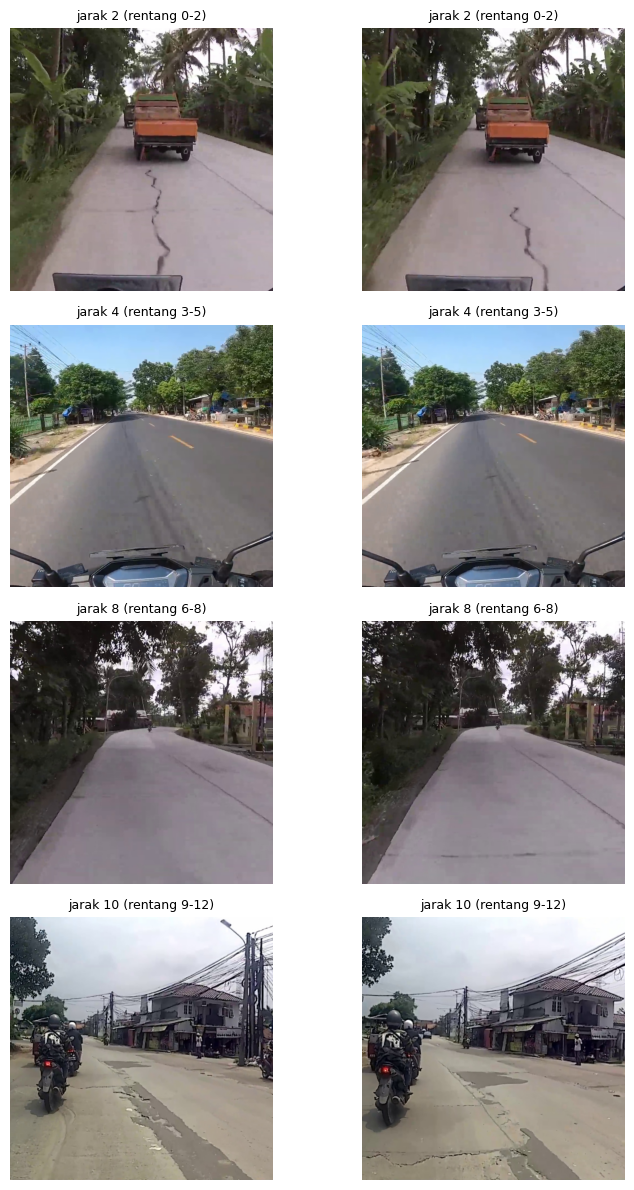

Kalau pasangan di suatu rentang masih 'adegan yang sama', TAU minimal sampai rentang itu.


In [6]:
# A5 · Lihat contoh pasangan per rentang jarak, buat menentukan TAU di sel A6
import matplotlib.pyplot as plt
def sample_pair(lo, hi):
    cand = df.index[(df.nn_dist >= lo) & (df.nn_dist <= hi)].tolist()
    if not cand: return None
    i = random.choice(cand)
    d = hamming_rows(H[i:i+1], H)[0].astype(int); d[i] = 99
    return i, int(d.argmin()), int(d.min())

bands = [(0, 2), (3, 5), (6, 8), (9, 12)]
fig, axes = plt.subplots(len(bands), 2, figsize=(8, 3 * len(bands)))
for row, (lo, hi) in enumerate(bands):
    pair = sample_pair(lo, hi)
    for col in range(2):
        ax = axes[row, col]; ax.axis("off")
        if pair:
            ax.imshow(Image.open(df.image[pair[col]])); ax.set_title(f"jarak {pair[2]} (rentang {lo}-{hi})", fontsize=9)
plt.tight_layout(); plt.show()
print("Kalau pasangan di suatu rentang masih 'adegan yang sama', TAU minimal sampai rentang itu.")

In [7]:
# A6 · Kelompokkan foto hampir kembar (jarak <= TAU)
TAU = 6   # ubah sesuai hasil sel A5, lalu jalankan ulang sel ini sampai A9

parent = list(range(len(H)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for s in range(0, len(H), 512):
    d = hamming_rows(H[s:s+512], H)
    rr, cc = np.nonzero(d <= TAU)
    for r_, c_ in zip(rr + s, cc):
        if c_ > r_:
            a, b = find(int(r_)), find(int(c_))
            if a != b: parent[b] = a
df["group"] = [find(i) for i in range(len(H))]
sizes = df.group.value_counts()
print(f"TAU = {TAU}: {len(df)} foto -> {len(sizes)} kelompok | kelompok >1 foto: {(sizes > 1).sum()} | terbesar: {sizes.max()}")

TAU = 6: 9048 foto -> 8472 kelompok | kelompok >1 foto: 351 | terbesar: 63


In [8]:
# A7 · Bagi 70:15:15 per kelompok, proporsi kelas dijaga
from sklearn.model_selection import StratifiedGroupKFold

def rarest_class(label_path):
    with open(label_path) as f:
        cs = {int(float(l.split()[0])) for l in f if l.strip()}
    return min(cs, key=lambda c: cls_counts[c]) if cs else len(CLASS_NAMES)

df["strat"] = [rarest_class(p) for p in df.label]
fold = np.empty(len(df), dtype=int)
for k, (_, idx) in enumerate(StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
                             .split(df, df.strat, df.group)):
    fold[idx] = k
df["split"] = np.where(fold < 3, "test", np.where(fold < 6, "val", "train"))
assert df.groupby("group").split.nunique().max() == 1, "Ada kelompok yang terbelah!"

def write_split(frame, prefix, yaml_name):
    for s in ["train", "val", "test"]:
        with open(os.path.join(DS, f"{prefix}{s}.txt"), "w") as f:
            f.write("\n".join(frame.loc[frame.split == s, "image"]) + "\n")
    with open(os.path.join(DS, yaml_name), "w") as f:
        f.write(f"path: '{DS.replace(os.sep, '/')}'\ntrain: {prefix}train.txt\nval: {prefix}val.txt\ntest: {prefix}test.txt\n")
        f.write("names:\n" + "".join(f"  {i}: {n}\n" for i, n in enumerate(CLASS_NAMES)))

def class_table(frame):
    out = {}
    for s in ["train", "val", "test"]:
        cnt = collections.Counter()
        for p in frame.loc[frame.split == s, "label"]:
            with open(p) as f:
                for l in f:
                    if l.strip(): cnt[int(float(l.split()[0]))] += 1
        out[s] = [cnt[i] for i in range(len(CLASS_NAMES))]
    t = pd.DataFrame(out, index=CLASS_NAMES)
    t.loc["Jumlah foto"] = [int((frame.split == s).sum()) for s in ["train", "val", "test"]]
    return t

write_split(df, "", "data.yaml")
display(class_table(df))

,train,val,test
Longitudinal Crack,3548,803,776
Lateral Crack,2395,490,547
Alligator Crack,2612,549,514
Pothole,4457,869,923
Other,1219,234,275
Jumlah foto,6398,1337,1313


In [9]:
# A8 · (Opsional) Pembagian acak tanpa pengelompokan, buat membandingkan efek kebocoran data
rnd = df.copy()
perm = np.random.RandomState(SEED).permutation(len(rnd))
n15 = int(0.15 * len(rnd))
rnd["split"] = "train"
rnd.iloc[perm[:n15], rnd.columns.get_loc("split")] = "test"
rnd.iloc[perm[n15:2 * n15], rnd.columns.get_loc("split")] = "val"
write_split(rnd, "random_", "data_random.yaml")
print(f"Pada pembagian acak, {(rnd.groupby('group').split.nunique() > 1).sum()} kelompok foto kembar terbelah.")

Pada pembagian acak, 173 kelompok foto kembar terbelah.


In [10]:
# A9 · Simpan ringkasan pembagian data
df.drop(columns=["phash"]).to_csv(os.path.join(PROJ, "split_kelompok.csv"), index=False)
n_img = len(os.listdir(os.path.join(DS, "images")))
print(f"Dataset siap di {DS}: {n_img} foto. Bagian A selesai, lanjut ke Bagian C.")
print("Kalau disk mepet, folder data/raw boleh dihapus sekarang (zip aslinya masih ada).")

Dataset siap di /home/galang/skripsi-training/Deteksi_Jalan/data/rddc: 9048 foto. Bagian A selesai, lanjut ke Bagian C.
Kalau disk mepet, folder data/raw boleh dihapus sekarang (zip aslinya masih ada).


---
## Bagian C · Training

Daftar eksperimen. Ganti `MODEL` dan `SKEMA` di sel C1, lalu jalankan C1 sampai C4. Satu eksperimen bisa makan beberapa jam (tergantung GPU), jadi colok charger dan atur supaya laptop tidak *sleep*.

Pengaturan: maksimal 15 epoch, *early stopping* (berhenti kalau 5 epoch berturut-turut tidak membaik). Tiap eksperimen menghasilkan:
- `best.pt`: model di epoch dengan mAP50-95 validasi tertinggi
- `last.pt`: model di epoch terakhir yang dijalankan
- `log_per_epoch.txt` dan `results.csv`: detail tiap epoch
- `grafik_per_epoch.png`: grafik loss dan metrik

Semuanya ada di `runs/<nama eksperimen>/`, dan salinan kedua model ada di `models/`.

| No | MODEL | SKEMA | Selesai |
|---|---|---|---|
| 1 | yolov8s.pt | A | ☐ |
| 2 | yolov8s.pt | B | ☐ |
| 3 | yolo11s.pt | A | * |
| 4 | yolo11s.pt | B | * |
| 5 | yolo26s.pt | A | ☐ |
| 6 | yolo26s.pt | B | ☐ |
| Opsional | yolo11s.pt | A, `SPLIT = "acak"` | ☐ |

Skema A = augmentasi bawaan YOLO. Skema B = bawaan + kecerahan, kontras, silau, bayangan.

In [11]:
# C1 · Pilih eksperimen
MODEL = "yolov8s.pt"     # "yolov8s.pt", "yolo11s.pt", atau "yolo26s.pt"
SKEMA = "A"              # "A" = augmentasi bawaan, "B" = bawaan + augmentasi cuaca
SPLIT = "kelompok"       # "kelompok" (utama) atau "acak" (opsional, pembanding kebocoran)

import albumentations as A
NAME = f"{os.path.splitext(MODEL)[0]}_{SKEMA}" + ("_acak" if SPLIT == "acak" else "")
DATA = os.path.join(DS, "data.yaml" if SPLIT == "kelompok" else "data_random.yaml")

EPOCHS = 15        # jumlah epoch maksimum
PATIENCE = 5       # early stopping: berhenti kalau 5 epoch berturut-turut mAP50-95 validasi tidak naik
CLOSE_MOSAIC = 3   # mosaic dimatikan di 3 epoch terakhir (bawaan 10, terlalu banyak untuk 15 epoch)

BATCH = 16         # kalau muncul "CUDA out of memory", turunkan ke 8 (lalu pakai 8 juga untuk semua eksperimen)
WORKERS = 4        # proses pembaca data. Kalau error DataLoader atau "paging file is too small", ganti ke 2 atau 0

COMMON = dict(data=DATA, epochs=EPOCHS, patience=PATIENCE, close_mosaic=CLOSE_MOSAIC,
              imgsz=640, batch=BATCH, workers=WORKERS, seed=SEED, optimizer="auto",
              project=RUNS, name=NAME, exist_ok=True)

AUG_B = [
    A.Blur(p=0.01), A.MedianBlur(p=0.01), A.ToGray(p=0.01), A.CLAHE(p=0.01),   # bawaan Ultralytics, tetap dipertahankan
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3),  # kecerahan dan kontras
        A.RandomSunFlare(flare_roi=(0, 0, 1, 0.5)),                            # silau dari arah langit
        A.RandomShadow(shadow_roi=(0, 0.5, 1, 1)),                              # bayangan di area jalan
    ], p=0.5),
]
print("Eksperimen:", NAME, "| data:", os.path.basename(DATA))

Eksperimen: yolov8s_A | data: data.yaml


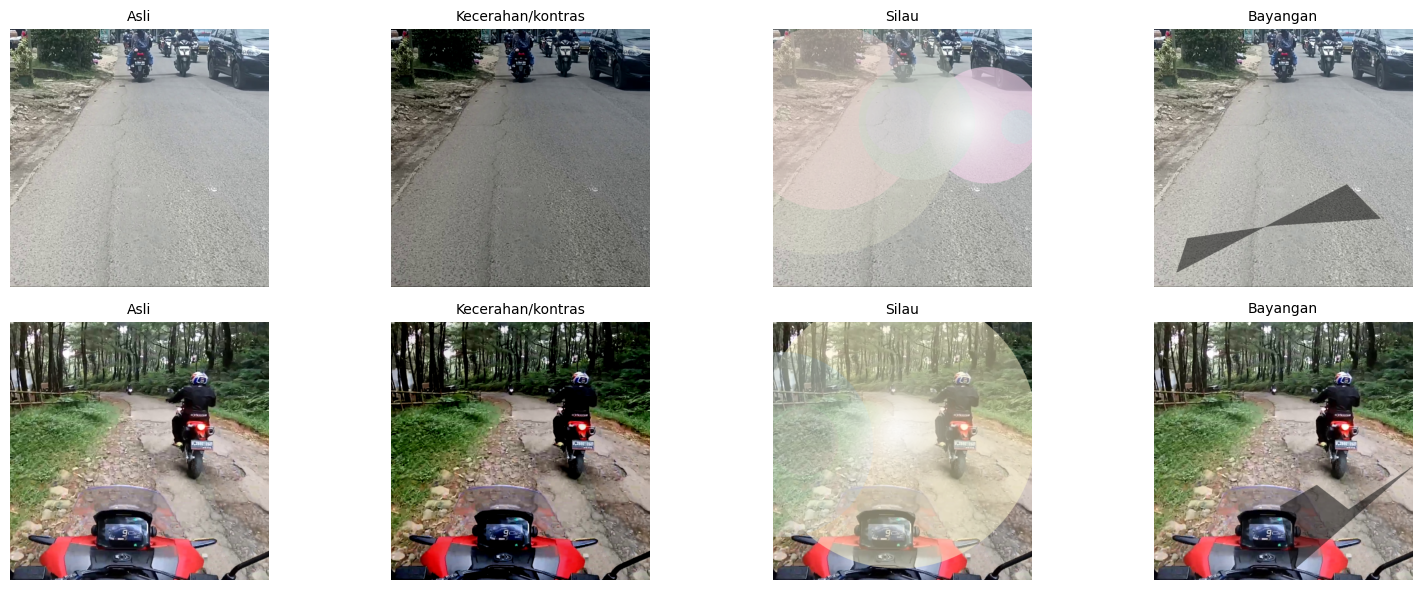

In [12]:
# C2 · (Opsional) Lihat contoh hasil augmentasi Skema B sebelum training
import matplotlib.pyplot as plt
samples = random.sample(open(os.path.join(DS, "train.txt")).read().splitlines(), 2)
previews = [("Asli", None),
            ("Kecerahan/kontras", A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=1)),
            ("Silau", A.RandomSunFlare(flare_roi=(0, 0, 1, 0.5), p=1)),
            ("Bayangan", A.RandomShadow(shadow_roi=(0, 0.5, 1, 1), p=1))]
fig, axes = plt.subplots(len(samples), len(previews), figsize=(4 * len(previews), 3 * len(samples)))
for r, path in enumerate(samples):
    img = np.array(Image.open(path).convert("RGB"))
    for c, (title, t) in enumerate(previews):
        ax = axes[r, c]; ax.axis("off"); ax.set_title(title, fontsize=10)
        ax.imshow(img if t is None else t(image=img)["image"])
plt.tight_layout(); plt.show()

In [13]:
# C3 · Training: early stopping, checkpoint best/last, log per epoch
import time, datetime, torch
from ultralytics import YOLO

RUN_DIR = os.path.join(RUNS, NAME)
MODELS = os.path.join(PROJ, "models")        # salinan model dengan nama jelas
os.makedirs(MODELS, exist_ok=True)

def log_write(tr, text):
    print(text)
    with open(os.path.join(tr.save_dir, "log_per_epoch.txt"), "a", encoding="utf-8") as f:
        f.write(text + "\n")

def log_header(tr):
    log_write(tr, f"=== {NAME} | mulai {datetime.datetime.now():%Y-%m-%d %H:%M} | epoch {tr.start_epoch + 1}-{tr.epochs} "
                  f"| patience {tr.args.patience} | optimizer {type(tr.optimizer).__name__} ===")

def log_epoch(tr):
    ep, m = tr.epoch + 1, tr.metrics or {}
    if getattr(tr, "_log_selesai", False):   # dipanggil lagi oleh validasi akhir best.pt setelah training
        log_write(tr, f"Validasi akhir best.pt (epoch {tr.stopper.best_epoch}): "
                      f"P {m.get('metrics/precision(B)', 0):.4f} R {m.get('metrics/recall(B)', 0):.4f} "
                      f"mAP50 {m.get('metrics/mAP50(B)', 0):.4f} mAP50-95 {m.get('metrics/mAP50-95(B)', 0):.4f}")
        return
    losses = tr.label_loss_items(tr.tloss, prefix="train")
    is_best = tr.fitness is not None and tr.best_fitness is not None and tr.fitness >= tr.best_fitness
    line = (f"Epoch {ep:>2}/{tr.epochs} | {tr.epoch_time:5.0f} dtk | "
            + " ".join(f"{k.split('/')[-1]} {float(v):.4f}" for k, v in losses.items())
            + f" | P {m.get('metrics/precision(B)', 0):.4f} R {m.get('metrics/recall(B)', 0):.4f}"
            + f" mAP50 {m.get('metrics/mAP50(B)', 0):.4f} mAP50-95 {m.get('metrics/mAP50-95(B)', 0):.4f}"
            + f" | lr {tr.lr.get('lr/pg0', 0):.6f}"
            + (" | TERBAIK -> best.pt" if is_best else f" | terbaik masih epoch {tr.stopper.best_epoch}"))
    log_write(tr, line)
    if tr.stop:
        tr._log_selesai = True
        if ep < tr.epochs:
            log_write(tr, f">>> Early stopping: {tr.args.patience} epoch tanpa peningkatan, training berhenti di epoch {ep}.")

def with_logging(model):
    model.add_callback("on_train_start", log_header)
    model.add_callback("on_fit_epoch_end", log_epoch)
    return model

def simpan_model():
    w = os.path.join(RUN_DIR, "weights")
    for src, tag in [("best.pt", "best"), ("last.pt", "last")]:
        shutil.copy2(os.path.join(w, src), os.path.join(MODELS, f"{NAME}_{tag}.pt"))
    res = pd.read_csv(os.path.join(RUN_DIR, "results.csv")); res.columns = res.columns.str.strip()
    b = res["metrics/mAP50-95(B)"].idxmax()
    print(f"\nEpoch terbaik: {int(res.loc[b, 'epoch'])} dari {len(res)} epoch "
          f"(mAP50-95 validasi {res.loc[b, 'metrics/mAP50-95(B)']:.4f})")
    print("Model terbaik :", os.path.join(MODELS, f"{NAME}_best.pt"))
    print("Model terakhir:", os.path.join(MODELS, f"{NAME}_last.pt"))

last = os.path.join(RUN_DIR, "weights", "last.pt")
status = "baru"
if os.path.exists(last):
    ck = torch.load(last, map_location="cpu", weights_only=False)
    status = "selesai" if ck.get("epoch", -1) == -1 else "lanjut"

if status == "selesai":
    print(f"{NAME} sudah selesai training. Kalau mau training ulang dari nol, hapus dulu folder {RUN_DIR}")
elif status == "lanjut":
    print(f"Melanjutkan {NAME} dari checkpoint terakhir...")
    with_logging(YOLO(last)).train(resume=True)
else:
    kwargs = dict(COMMON)
    if SKEMA == "B":
        kwargs["augmentations"] = AUG_B
    with_logging(YOLO(MODEL)).train(**kwargs)
simpan_model()

yolov8s_A sudah selesai training. Kalau mau training ulang dari nol, hapus dulu folder /home/galang/skripsi-training/Deteksi_Jalan/runs/yolov8s_A

Epoch terbaik: 15 dari 15 epoch (mAP50-95 validasi 0.0890)
Model terbaik : /home/galang/skripsi-training/Deteksi_Jalan/models/yolov8s_A_best.pt
Model terakhir: /home/galang/skripsi-training/Deteksi_Jalan/models/yolov8s_A_last.pt


=== yolov8s_A | mulai 2026-10-31 01:50 | epoch 1-15 | patience 5 | optimizer AdamW ===
Epoch  1/15 |   205 dtk | box_loss 2.0389 cls_loss 3.5636 dfl_loss 1.9539 | P 0.0925 R 0.1403 mAP50 0.0490 mAP50-95 0.0179 | lr 0.000369 | TERBAIK -> best.pt
Epoch  2/15 |   172 dtk | box_loss 2.0586 cls_loss 3.0993 dfl_loss 1.9790 | P 0.1365 R 0.1223 mAP50 0.0748 mAP50-95 0.0252 | lr 0.000691 | TERBAIK -> best.pt
Epoch  3/15 |   181 dtk | box_loss 2.0461 cls_loss 3.0724 dfl_loss 1.9743 | P 0.1361 R 0.1432 mAP50 0.0775 mAP50-95 0.0270 | lr 0.000964 | TERBAIK -> best.pt
Epoch  4/15 |   176 dtk | box_loss 2.0059 cls_loss 3.0000 dfl_loss 1.9396 | P 0.2690 R 0.1641 mAP50 0.0950 mAP50-95 0.0359 | lr 0.000891 | TERBAIK -> best.pt
Epoch  5/15 |   178 dtk | box_loss 1.9590 cls_loss 2.9357 dfl_loss 1.8957 | P 0.1892 R 0.2168 mAP50 0.0962 mAP50-95 0.0380 | lr 0.000818 | TERBAIK -> best.pt
Epoch  6/15 |   177 dtk | box_loss 1.8994 cls_loss 2.8625 dfl_loss 1.8525 | P 0.2167 R 0.2119 mAP50 0.1253 mAP50-95 0.0505 

,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0
epoch,,,,,,,,,,,
1,2.0389,3.5636,1.9539,0.0925,0.1403,0.0490,0.0179,2.3455,3.9304,2.3053,0.0004
2,2.0586,3.0993,1.9790,0.1365,0.1223,0.0748,0.0252,2.2761,3.2490,2.1788,0.0007
3,2.0461,3.0724,1.9743,0.1362,0.1432,0.0775,0.0270,2.2381,3.4727,2.1615,0.0010
4,2.0059,3.0000,1.9396,0.2690,0.1641,0.0950,0.0359,2.1555,3.1825,2.1051,0.0009
5,1.9590,2.9357,1.8957,0.1892,0.2168,0.0962,0.0380,2.1041,3.3044,2.0508,0.0008
6,1.8994,2.8625,1.8525,0.2166,0.2118,0.1253,0.0505,2.0375,2.9880,2.0096,0.0007
7,1.8704,2.7954,1.8308,0.2349,0.2140,0.1421,0.0575,2.0269,2.8528,1.9698,0.0007
8,1.8488,2.7506,1.8050,0.2569,0.2266,0.1394,0.0582,1.9740,2.8209,1.9289,0.0006
9,1.8288,2.7186,1.7917,0.2498,0.2181,0.1458,0.0632,1.9848,2.7659,1.9686,0.0005


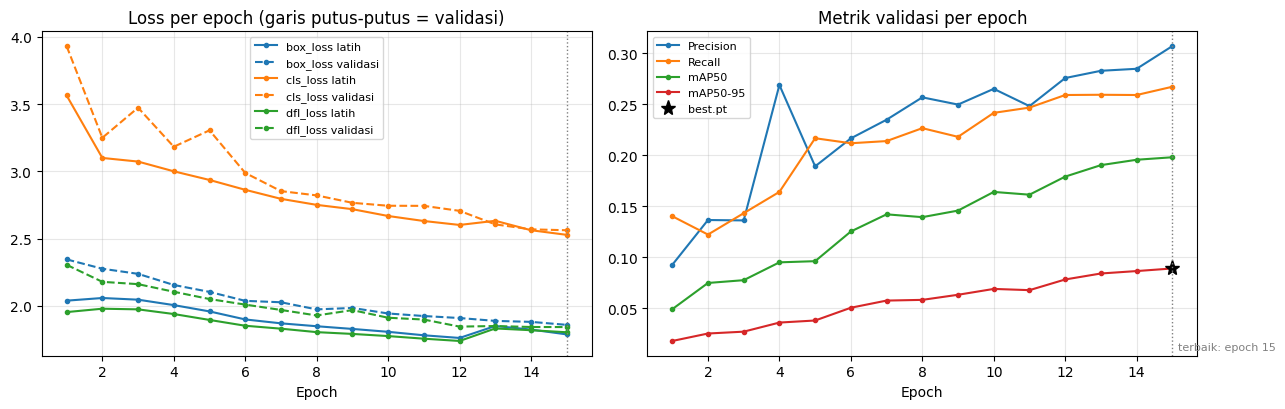

In [14]:
# C4 · Lihat log dan grafik per epoch
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
log_path = os.path.join(RUN_DIR, "log_per_epoch.txt")
if os.path.exists(log_path):
    print(open(log_path, encoding="utf-8").read())

res = pd.read_csv(os.path.join(RUN_DIR, "results.csv")); res.columns = res.columns.str.strip()
ib = res["metrics/mAP50-95(B)"].idxmax(); best_ep = int(res.loc[ib, "epoch"])
display(res.drop(columns=["time", "lr/pg1", "lr/pg2"], errors="ignore").set_index("epoch").round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for k, color in [("box_loss", "C0"), ("cls_loss", "C1"), ("dfl_loss", "C2")]:
    ax1.plot(res.epoch, res[f"train/{k}"], color=color, marker="o", ms=3, label=f"{k} latih")
    ax1.plot(res.epoch, res[f"val/{k}"], color=color, marker="o", ms=3, ls="--", label=f"{k} validasi")
ax1.set_title("Loss per epoch (garis putus-putus = validasi)")
for col, lab in [("metrics/precision(B)", "Precision"), ("metrics/recall(B)", "Recall"),
                 ("metrics/mAP50(B)", "mAP50"), ("metrics/mAP50-95(B)", "mAP50-95")]:
    ax2.plot(res.epoch, res[col], marker="o", ms=3, label=lab)
ax2.plot(best_ep, res.loc[ib, "metrics/mAP50-95(B)"], "k*", ms=11, label="best.pt")
ax2.set_title("Metrik validasi per epoch")
for ax in (ax1, ax2):
    ax.axvline(best_ep, color="gray", ls=":", lw=1)
    ax.set_xlabel("Epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax2.annotate(f"terbaik: epoch {best_ep}", xy=(best_ep, 0), xycoords=("data", "axes fraction"),
             xytext=(4, 4), textcoords="offset points", fontsize=8, color="gray")
plt.tight_layout()
plt.savefig(os.path.join(RUN_DIR, "grafik_per_epoch.png"), dpi=150)
plt.show()

---
## Bagian D · Evaluasi di data uji

Evaluasi memakai `best.pt`. Model ini dipilih berdasarkan data validasi, jadi data uji tetap belum pernah dipakai sama sekali selama training dan hasilnya adil.

In [15]:
# D1 · Evaluasi model terbaik di data uji, simpan ke hasil_evaluasi.csv
from ultralytics import YOLO
best = os.path.join(RUNS, NAME, "weights", "best.pt")
m = YOLO(best).val(data=DATA, split="test", imgsz=640, batch=BATCH, workers=WORKERS,
                   project=os.path.join(PROJ, "eval"), name=NAME, exist_ok=True)

P, R = m.results_dict["metrics/precision(B)"], m.results_dict["metrics/recall(B)"]
row = {"eksperimen": NAME, "model": MODEL, "skema": SKEMA, "split": SPLIT,
       "precision": P, "recall": R, "F1": 2 * P * R / (P + R) if P + R else 0.0,
       "mAP50": m.results_dict["metrics/mAP50(B)"], "mAP50-95": m.results_dict["metrics/mAP50-95(B)"],
       "inferensi_ms_per_foto": m.speed["inference"]}
ap50 = dict(zip([int(i) for i in m.box.ap_class_index], [float(v) for v in m.box.ap50]))
for i, n in enumerate(CLASS_NAMES):
    row[f"AP50 {n}"] = ap50.get(i, float("nan"))

csv_path = os.path.join(PROJ, "hasil_evaluasi.csv")
hasil = pd.read_csv(csv_path) if os.path.exists(csv_path) else pd.DataFrame()
if len(hasil):
    hasil = hasil[hasil.eksperimen != NAME]
hasil = pd.concat([hasil, pd.DataFrame([row])], ignore_index=True)
hasil.to_csv(csv_path, index=False)
display(pd.DataFrame([row]).T.rename(columns={0: NAME}))

Ultralytics 8.4.190 🚀 Python-3.10.22 torch-2.6.0+cu118 CUDA:0 (NVIDIA GeForce GTX 1080 Ti, 11264MiB)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2526.6±2143.0 MB/s, size: 632.4 KB)
val: Scanning /home/galang/skripsi-training/Deteksi_Jalan/data/rddc/labels... 1313 images, 298 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1313/1313 164.0it/s 8.0s0.1s
val: New cache created: /home/galang/skripsi-training/Deteksi_Jalan/data/rddc/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 83/83 4.0it/s 20.9s0.2ss
                   all       1313       3035      0.286      0.265      0.193     0.0853
    Longitudinal Crack        477        776      0.342      0.403      0.292      0.148
         Lateral Crack        308        547      0.266      0.325      0.212     0.0761
       Alligator Crack        306        514      0.319      0.253      0.

,yolov8s_A
eksperimen,yolov8s_A
model,yolov8s.pt
skema,A
split,kelompok
precision,0.286382
recall,0.264881
F1,0.275212
mAP50,0.19281
mAP50-95,0.085337
inferensi_ms_per_foto,6.933162


In [16]:
# D2 · Tabel semua eksperimen yang sudah dievaluasi
display(pd.read_csv(os.path.join(PROJ, "hasil_evaluasi.csv")).round(4))

,eksperimen,model,skema,split,precision,recall,F1,mAP50,mAP50-95,inferensi_ms_per_foto,AP50 Longitudinal Crack,AP50 Lateral Crack,AP50 Alligator Crack,AP50 Pothole,AP50 Other
0,yolo11s_A,yolo11s.pt,A,kelompok,0.2944,0.2533,0.2723,0.1898,0.0843,6.1153,0.2778,0.2161,0.1998,0.1820,0.0734
1,yolo11s_B,yolo11s.pt,B,kelompok,0.2844,0.2615,0.2724,0.1809,0.0827,7.1524,0.2795,0.1855,0.1898,0.1719,0.0780
2,yolov8s_A,yolov8s.pt,A,kelompok,0.2864,0.2649,0.2752,0.1928,0.0853,6.9332,0.2917,0.2121,0.1948,0.1933,0.0722


---
### Catatan
- Training bisa dihentikan kapan saja (tombol **Interrupt** / ■ di toolbar). Checkpoint tersimpan tiap epoch, jadi jalankan Sel 1 → C1 → C3 lagi untuk melanjutkan. Log per epoch tetap nyambung.
- Supaya laptop tidak *sleep* saat training: **Settings → System → Power & battery → Screen, sleep & hibernate** → set **Never** saat dicolok charger.
- `CUDA out of memory` → ubah `BATCH` di C1 jadi 8. Pakai angka yang sama untuk semua eksperimen biar perbandingannya adil.
- Error DataLoader atau `paging file is too small` → ubah `WORKERS` di C1 jadi 2 atau 0.
- Untuk GTX 1080 Ti gunakan wheel CUDA 11.8 (`cu118`) yang sudah dipilih dalam Sel 0. Jika `pip` terputus, lanjutkan percobaan di terminal dengan opsi `--timeout 120 --resume-retries 25`.
- Sel 0 gagal dengan `Access is denied` → restart kernel, lalu jalankan Sel 0 paling pertama sebelum sel lain.
- Grafik bawaan Ultralytics (kurva loss, PR curve, confusion matrix) juga tersimpan di `runs/<nama eksperimen>/`.
- Tahap berikutnya: evaluasi di BPID per kondisi cuaca (notebook terpisah).